# Retener un muestreo: qué predice la columna vertebral calibrada para una planta que no ha visto

**Pregunta:** Cuando la columna vertebral calibrada se reajusta sin un muestreo, ¿qué tan bien predice el tonelaje de ese muestreo, y cuánto mejor es eso que adivinar el promedio de los demás?

- **Nivel:** 1, Fundamentos
- **Requisitos previos:** los notebooks 01 y 02 del tema 05-real-surveys
- **Tiempo de lectura:** unos 30 minutos

## Objetivos

Al terminar este notebook usted puede:

- explicar qué es un pliegue de dejar un muestreo fuera, y decir qué filas ajusta y cuál predice;
- leer la predicción retenida de la columna vertebral calibrada para cada uno de los diez muestreos;
- compararla con la línea base de media constante que daría un modelo sin habilidad;
- decir cuánto adula el juicio dentro de la muestra al mismo modelo.

## Preparación

Numpy y matplotlib.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

Las importaciones son el lector de muestreos y los dos constructores de la carpeta `hp500` del pipeline: la columna vertebral y CrusherCal.

In [1]:
# Imprima las versiones de las herramientas de este notebook, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib'):
    print(name, md.version(name))

# El notebook está tres carpetas bajo la raíz del repositorio; el pipeline se importa por su ruta
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.hp500.surveys import read_surveys
from pipeline.hp500 import backbone, loo
from pipeline.model.crusher.capacity import HP500_QREF
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

numpy 2.4.6
matplotlib 3.11.2


## Datos

Los diez muestreos del HP500, los resultados del motor en ellos y el documento de CrusherCal versionado. Propietario: Rocha, Campos, Silva y Tavares (2024), Minerals 14(9), 919, https://doi.org/10.3390/min14090919. Clase de licencia: CC BY 4.0 (acceso abierto, atribución), véase `conventions/third-party-datasets.md`; las diez filas de muestreos se transcriben de la Tabla A1 del artículo. Archivos leídos: `data/examples/hp500-surveys.csv`, `data/derived/hp500/backbone.json` y `data/derived/hp500/loo.json` (contrato `hp500-loo`), este último solo para comprobar que el cálculo en vivo lo reproduce.

La celda siguiente lee todo y corre toda la validación en vivo. El documento que construye es el versionado, que es la única comprobación de reproducción del notebook; todo lo que sigue usa el documento vivo.

In [2]:
# Reconstruya en vivo la columna vertebral y el documento de CrusherCal desde la tabla de muestreos; deben ser los versionados
surveys = read_surveys().accepted
version = json.loads((ROOT / "data" / "derived" / "hp500" / "backbone.json").read_text(encoding="utf-8"))["engine_version"]
live_backbone = backbone.build(surveys, version)
doc = loo.build(live_backbone, version)
committed = json.loads((ROOT / "data" / "derived" / "hp500" / "loo.json").read_text(encoding="utf-8"))
print("el documento de CrusherCal reconstruido es igual al versionado:", doc == committed, "| muestreos:", doc["n"])

el documento de CrusherCal reconstruido es igual al versionado: True | muestreos: 10


## Método

**Paso 1, el pliegue.** Un modelo que se ajusta a diez muestreos y se juzga con los mismos diez dice qué tan bien los describe, no cómo le iría con un undécimo. El protocolo de dejar un muestreo fuera responde la segunda pregunta: para cada muestreo $i$, ajustar con los otros nueve y predecir $i$, y luego juzgar juntas las diez predicciones. El único número libre de la columna vertebral para el tonelaje es la base de capacidad $Q_T$, que cada pliegue reajusta a sus nueve muestreos por mínimos cuadrados. El código CrusherCal del pipeline construye los pliegues con un ayudante, y la celda imprime las filas de entrenamiento del muestreo 3 en el pliegue estricto y en la variante con fuga, que mantiene el muestreo en su propio conjunto de entrenamiento y existe para medir cuánto adula eso a un modelo.

In [3]:
# Filas de entrenamiento del muestreo 3 (índice 2) en el pliegue estricto y en la variante con fuga
print("pliegue estricto, filas ajustadas:", loo._loo_indices(10, 2, leaky=False).tolist())
print("variante con fuga, filas ajustadas:", loo._loo_indices(10, 2, leaky=True).tolist())

pliegue estricto, filas ajustadas: [0, 1, 3, 4, 5, 6, 7, 8, 9]
variante con fuga, filas ajustadas: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


Las dos predicciones para el muestreo 3 se pueden hacer con las propias funciones de modelo del pipeline, que `loo.build` llama pliegue por pliegue: la columna vertebral M0, cuya predicción es la base de capacidad ajustada a las filas de entrenamiento por el factor de capacidad del muestreo, y la regresión sin restricciones M2 sobre la abertura y el f80. La celda pide ambas en el pliegue estricto y en el con fuga, junto a la medición.

In [4]:
# Prediga el muestreo 3 con las funciones M0 y M2 del pipeline, en el pliegue estricto y en la variante con fuga
shape = np.array([s["backbone"]["throughput_tph"] for s in live_backbone["surveys"]]) / HP500_QREF
measured = np.array([s.feed_tph for s in surveys])
features = np.column_stack([[s.css_mm for s in surveys], [s.f80_mm for s in surveys]])
for name, leaky in (("strict", False), ("leaky", True)):
    rows = loo._loo_indices(10, 2, leaky=leaky)
    print(f"{name:7s} M0 {loo._m0_tph(shape, measured, 2, rows):7.1f} t/h   M2 {loo._m2_freeform(features, measured, 2, rows):7.1f} t/h   medido {measured[2]:.0f} t/h")

strict  M0  1165.8 t/h   M2   981.0 t/h   medido 1240 t/h
leaky   M0  1173.4 t/h   M2  1078.3 t/h   medido 1240 t/h


El pliegue con fuga, que ha visto el muestreo 3, queda más cerca de la medición que el estricto en ambos modelos, y la regresión sin restricciones es la que más gana con la fuga, porque tiene más coeficientes que doblar hacia el punto que vio. La base de capacidad de la columna vertebral es el único número que cada pliegue reajusta, y la celda siguiente la imprime para los diez pliegues estrictos.

In [5]:
# La base de capacidad reajustada por cada uno de los diez pliegues estrictos
bases = [loo._m0_tph(shape, measured, i, loo._loo_indices(10, i, False)) / shape[i] for i in range(10)]
print("base de capacidad reajustada por pliegue [t/h]:", np.round(bases, 1))
print("rango:", round(min(bases), 1), "to", round(max(bases), 1), "| el valor del artículo:", HP500_QREF)

base de capacidad reajustada por pliegue [t/h]: [659.3 687.1 681.5 695.3 689.3 698.3 682.9 683.7 697.9 683.4]
rango: 659.3 to 698.3 | el valor del artículo: 647


La base se mueve entre 659 y 698 t/h de un pliegue a otro, una dispersión de cerca de 6 por ciento producida al quitar un muestreo de diez, y todos los pliegues quedan sobre los 647 t/h del artículo: eso es lo que mueve un ajuste de un parámetro con diez puntos, y la incertidumbre que lleva un solo valor dentro de la muestra y que el protocolo con datos retenidos hace visible.

**Paso 2, las predicciones retenidas.** El documento guarda, para el objetivo de tonelaje, los valores medidos y las predicciones retenidas de cada modelo en los pliegues estrictos. La celda lista la predicción de la columna vertebral (M0) para cada muestreo junto a la medición y el residuo, lo medido menos lo predicho, y calcula el error porcentual absoluto medio. Un muestreo con un residuo grande es uno para el que los otros nueve no prepararon al modelo.

In [6]:
# Liste la predicción retenida de la columna vertebral para cada muestreo junto a la medición
target = doc["loo"]["tph"]
measured = np.array(target["measured"])
held_out = np.array(target["strict"]["pred"]["M0"])
print("muestreo  medido   retenido   residuo")
for s, m, p in zip(surveys, measured, held_out):
    print(f"{s.survey:6d} {m:9.0f} {p:9.1f} {m - p:+9.1f}")
print("MAPE retenido de la columna vertebral:", target["strict"]["M0_backbone"]["mape_pct"], "%")

muestreo  medido   retenido   residuo
     1      1639    1231.9    +407.1
     2      1267    1283.8     -16.8
     3      1240    1165.8     +74.2
     4      1034    1189.3    -155.3
     5      1124    1179.1     -55.1
     6       813    1047.5    -234.5
     7      1050     988.4     +61.6
     8      1138    1097.5     +40.5
     9       820    1046.9    -226.9
    10      1334    1294.8     +39.2
MAPE retenido de la columna vertebral: 12.09 %


Los residuos son de ambos signos y de tamaños muy distintos: el muestreo 1 es el extremo, 407 t/h sobre lo que predicen los otros nueve, y los muestreos 6 y 9, con 40 mm y 813 y 820 t/h, están unos 230 t/h bajo. La figura pone las predicciones retenidas en un gráfico de paridad frente a las mediciones, con la banda de 29 por ciento que usó la compuerta de expectativas del notebook 02 del tema 05.

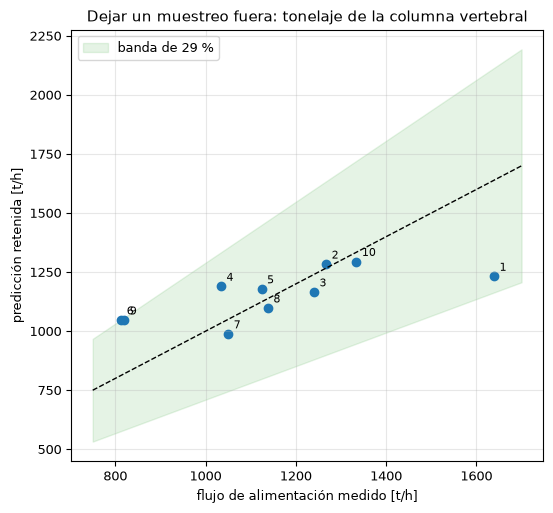

In [7]:
# Gráfico de paridad de las predicciones retenidas de la columna vertebral contra el tonelaje medido, con la banda de 29 %
fig, ax = plt.subplots(figsize=(5.6, 5.2))
line = np.array([750, 1700])
ax.fill_between(line, line * 0.71, line * 1.29, color="tab:green", alpha=0.12, label="banda de 29 %")
ax.plot(line, line, "k--", lw=1)
ax.scatter(measured, held_out)
for s, m, p in zip(surveys, measured, held_out):
    ax.annotate(str(s.survey), (m, p), xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.set_xlabel("flujo de alimentación medido [t/h]")
ax.set_ylabel("predicción retenida [t/h]")
ax.set_title("Dejar un muestreo fuera: tonelaje de la columna vertebral")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

Los diez puntos caen dentro de la banda verde, y tres de ellos cerca de su borde: el muestreo 1 queda 24,8 por ciento bajo su medición (1232 frente a 1639 t/h), y los muestreos 6 y 9 quedan 28,8 y 27,7 por ciento sobre las suyas. Las predicciones ocupan un rango angosto, de 988 a 1295 t/h, mucho más angosto que las mediciones, porque la columna vertebral solo conoce la abertura. Lo que la figura no puede decir es si esto es bueno: un modelo que predijera siempre el mismo número también caería dentro de una banda ancha. La comparación con ese modelo es el paso siguiente.

**Paso 3, la línea base y el optimismo.** Un modelo sin habilidad predice, para el muestreo retenido, el promedio de los otros nueve: la línea base de media constante. Un modelo que valga algo debe superarla, con datos retenidos. El mismo documento contiene los números dentro de la muestra (con fuga), así que la celda compara cuatro modelos en ambos protocolos: la columna vertebral M0, la columna vertebral más un residuo acotado M1, una regresión sin restricciones M2 y la línea base. La figura dibuja los pares.

M0_backbone    retenido  12.09 %   dentro de la muestra  10.95 %   optimismo +1.14
M1_residual    retenido  13.45 %   dentro de la muestra   8.51 %   optimismo +4.94
M2_freeform    retenido  12.18 %   dentro de la muestra   8.24 %   optimismo +3.94
constant_mean  retenido  18.29 %   dentro de la muestra  16.46 %   optimismo +1.83


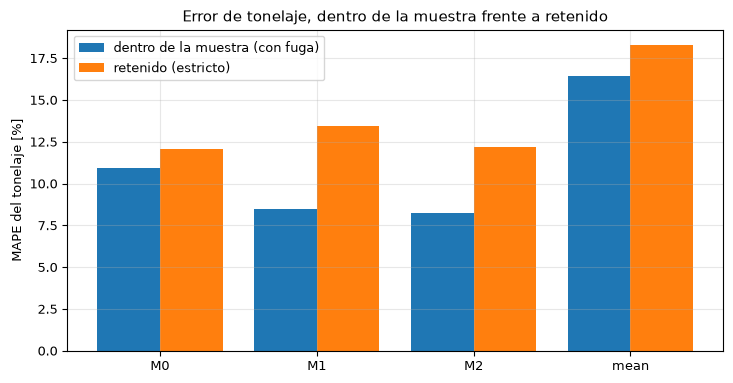

In [8]:
# MAPE retenido (estricto) y dentro de la muestra (con fuga) de los cuatro modelos para el tonelaje, y el gráfico de barras
names = ("M0_backbone", "M1_residual", "M2_freeform", "constant_mean")
strict = [target["strict"][m]["mape_pct"] for m in names]
leaky = [target["leaky"][m]["mape_pct"] for m in names]
for m, a, b in zip(names, strict, leaky):
    print(f"{m:14s} retenido {a:6.2f} %   dentro de la muestra {b:6.2f} %   optimismo {a - b:+5.2f}")
x = np.arange(len(names))
fig, ax = plt.subplots()
ax.bar(x - 0.2, leaky, 0.4, label="dentro de la muestra (con fuga)")
ax.bar(x + 0.2, strict, 0.4, label="retenido (estricto)")
ax.set_xticks(x, [m.split("_")[0] if m != "constant_mean" else "mean" for m in names])
ax.set_ylabel("MAPE del tonelaje [%]")
ax.set_title("Error de tonelaje, dentro de la muestra frente a retenido")
ax.legend()
fig.tight_layout()
plt.show()

Todos los modelos se ven peor con datos retenidos que dentro de la muestra, que es lo que el protocolo existe para mostrar, y la brecha no es igual para todos. La columna vertebral pierde 1,1 puntos, la línea base 1,8, y los dos modelos con parámetros libres pierden 4,9 (M1) y 3,9 (M2): a más libertad, más adulaba el número dentro de la muestra. Con datos retenidos, los tres modelos están a menos de 1,4 puntos entre sí, 12,1, 13,5 y 12,2 por ciento, y los tres quedan claramente bajo la línea base de 18,3 por ciento. La columna vertebral tiene habilidad real, y la regresión sin restricciones con sus tres coeficientes ajustados no es mejor que la física una vez retenida. La figura muestra el orden; no muestra qué tan estable es con diez puntos, que es lo que examina el notebook 02.

## Resultados

**Respuesta:** con datos retenidos, la columna vertebral calibrada predice el tonelaje de un muestreo con un error absoluto medio de 12,09 por ciento, frente a 18,29 por ciento para el promedio de los otros nueve, y 10,95 por ciento dentro de la muestra. Las diez predicciones retenidas quedan a menos de 29 por ciento de la medición, y los tres mayores errores son los muestreos 1, 6 y 9 (24,8, 28,8 y 27,7 por ciento); el muestreo 1 está 407 t/h sobre su predicción. El optimismo del juicio dentro de la muestra es 1,14 puntos para la columna vertebral y 4,94 para el modelo con residuo libre.

La figura de paridad muestra una banda angosta de predicciones frente a una banda ancha de mediciones, y el gráfico de barras el orden de tres vías con datos retenidos. Un validador concluiría que la columna vertebral del tonelaje tiene una habilidad que sobrevive a la retención, que agregar parámetros libres no compró nada fuera de la muestra, y que el cálculo en vivo reproduce el documento versionado. Los límites honestos: diez muestreos de una máquina hacen cada número grueso, y el protocolo con datos retenidos puede decir cómo le va a la columna vertebral con un muestreo nuevo de este chancador y este mineral, no con otra máquina.

## Resumen

Un pliegue de dejar un muestreo fuera reajusta la base de capacidad de la columna vertebral con nueve muestreos y predice el décimo. En tonelaje la columna vertebral supera a la línea base de promedio con datos retenidos por 6 puntos y es tan buena como una regresión sin restricciones, que se adula mucho más dentro de la muestra. El notebook 02 pregunta cuánto confiar en eso con diez puntos, con la comparación con fuga para los dos objetivos, el control de barajado y el modelo de residuo.

## Referencias

- Rocha, B. K. N., Campos, T. M., Silva, J., Tavares, L. M. (2024), Fit-for-Purpose Model of HP500 Cone Crusher in Size Reduction of Itabirite Iron Ore, Minerals 14(9), 919. https://doi.org/10.3390/min14090919